# Certamen 1 · Ensambles, costo de clasificación y umbral óptimo

**Grupo 15** · Machine Learning · Profesor: Danilo Gómez Correa

**Integrantes:** Felipe Alonso, Sofía Fariña y Vicente Lagunas

**Dashboard:** https://certamen1-grupo15.streamlit.app

**Base de datos:** Health Insurance Cross Sell Prediction (Kaggle)

> *Del dato a la decisión:* comparamos 5 modelos con 2 estrategias de desbalance, elegimos el mejor por validación cruzada y traducimos sus errores a dinero para encontrar el umbral que minimiza el costo.

**Estructura del notebook**
1. Problema de negocio y base de datos
2. Exploración y pipeline
3. Etapa A: 5 modelos con SMOTE
4. Etapa B: 5 modelos con pesos
5. Tabla de las 10 combinaciones y mejor modelo
6. Matriz de costos en dinero
7. Umbral teórico, empírico y ahorro
8. Sensibilidad a la razón FN/FP
9. Dashboard

## 1. Problema de negocio y base de datos

**Contexto.** Una aseguradora que vende seguros de salud quiere ofrecer también un **seguro de vehículo** a sus clientes (*venta cruzada*). Para eso los llama por teléfono. Cada llamada cuesta dinero, pero no llamar a alguien que sí habría comprado significa perder una venta.

**Pregunta de negocio:** ¿a qué clientes conviene llamar para gastar lo menos posible?

**Variable objetivo (`Response`):**
- `1` = el cliente se interesa en el seguro de vehículo
- `0` = no se interesa

**Los dos errores posibles:**
- **Falso positivo (FP):** llamamos a alguien que no compra → perdemos el costo de la llamada.
- **Falso negativo (FN):** no llamamos a alguien que sí habría comprado → perdemos la ganancia de esa venta.

Como el FN es mucho más caro que el FP, **el umbral 0,5 no será el mejor** (lo demostraremos en la sección 7).

**Fuente:** [Kaggle · Health Insurance Cross Sell Prediction](https://www.kaggle.com/datasets/anmolkumar/health-insurance-cross-sell-prediction). Usamos solo `train.csv`, porque `test.csv` no trae la variable objetivo. Nuestra propia partición 80/20 hará de test.

### 1.1 Librerías
Importamos todo lo que usaremos en el notebook. Fijamos una **semilla** para que los resultados sean reproducibles (el enunciado lo exige en la partición, SMOTE, la validación cruzada y los modelos).

In [ ]:
# Librerías clásicas
import os, time, joblib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Partición, validación cruzada, búsqueda de hiperparámetros y umbral
from sklearn.model_selection import (train_test_split, StratifiedKFold, RandomizedSearchCV,
                                     TunedThresholdClassifierCV,
                                     cross_val_predict) #Para la sensibilidad
from sklearn.base import clone

# Preprocesamiento (todo irá DENTRO del pipeline para evitar fuga de datos
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as SkPipeline

# Balanceo y Pipeline de imblearn (acepta SMOTE como paso)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

#  Los 5 modelos obligatorios
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier #El enunciado exige LightGBM como 5º modelo

# --- Métricas ---
from sklearn.metrics import (f1_score, recall_score, precision_score, roc_auc_score, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay, make_scorer)

# --- Configuración ---
warnings.filterwarnings("ignore")   # ocultar avisos
plt.style.use("ggplot")             # estilo de gráficos
SEED = 2026                         # semilla fija
np.random.seed(SEED)

### 1.2 Carga de datos
Leemos `train.csv` desde Google Drive. Eliminamos la columna `id` porque es solo un número de fila: no aporta información para predecir.

In [ ]:
# Conectar Google Drive (igual que en clases)
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Leer la base desde la carpeta de Drive
ruta = "/content/drive/MyDrive/Certamen1_ML/train.csv"
df = pd.read_csv(ruta)

# 'id' es solo un identificador de fila: no sirve para predecir
df = df.drop(columns="id") #eliminar

# Primeros números de la ficha de la base
print(f"Registros: {len(df):,}")
print(f"Variables predictoras: {df.shape[1] - 1}")
print(f"Clase minoritaria (Response = 1): {df['Response'].mean():.2%}")
df.head()

Registros: 381,109
Variables predictoras: 10
Clase minoritaria (Response = 1): 12.26%


,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,Male,44,1,28.0,0,> 2 Years,Yes,40454.0,26.0,217,1
1,Male,76,1,3.0,0,1-2 Year,No,33536.0,26.0,183,0
2,Male,47,1,28.0,0,> 2 Years,Yes,38294.0,26.0,27,1
3,Male,21,1,11.0,1,< 1 Year,No,28619.0,152.0,203,0
4,Female,29,1,41.0,1,< 1 Year,No,27496.0,152.0,39,0


### 1.3 Ficha de la base

| Requisito | Mínimo exigido | Nuestra base | ¿Cumple? |
|---|---|---|---|
| Tamaño | > 100.000 registros | 380.840 (tras eliminar 269 duplicados) | SÍ |
| Variable objetivo | Binaria (0/1) | `Response` (0/1) | SÍ |
| Desbalance | Minoritaria entre 1% y 30% | 12,26% | SÍ |
| Variables predictoras | Al menos 8 | 10 | SÍ |
| Contexto de negocio | Costo en dinero para FP y FN | Llamada inútil vs. venta perdida | SÍ |
| Restricción | No usar `banco.csv` | Base de Kaggle | SÍ |

> En la sección 2 se eliminan 269 filas duplicadas; la base sigue muy por sobre 100.000 registros.

### 1.4 Diccionario de variables

| Variable | Tipo | Significado | Observación |
|---|---|---|---|
| `Gender` | Categórica binaria | Género del cliente (Male / Female) | Se convierte a 0/1 en el pipeline |
| `Age` | Numérica | Edad | — |
| `Driving_License` | Binaria | 1 = tiene licencia, 0 = no tiene | Casi todos tienen licencia (99,8 %): aporta poca información |
| `Region_Code` | Categórica (código) | Región donde vive | Es un código, no una cantidad |
| `Previously_Insured` | Binaria | 1 = ya tiene seguro de vehículo, 0 = no tiene | Bien repartida (46 % / 54 %) |
| `Vehicle_Age` | Categórica | Antigüedad del vehículo (< 1, 1-2, > 2 años) | — |
| `Vehicle_Damage` | Categórica binaria | Yes = su vehículo tuvo daños, No = no tuvo | Se convierte a 0/1 en el pipeline |
| `Annual_Premium` | Numérica | Prima anual que paga por su seguro de salud | — |
| `Policy_Sales_Channel` | Categórica (código) | Canal por el que se contactó al cliente | Es un código, no una cantidad |
| `Vintage` | Numérica | Días que lleva como cliente | — |
| **`Response`** | **Objetivo binaria** | **1 = se interesa, 0 = no se interesa** | **Desbalanceada: 12,26 % de 1** |

## 2. Exploración y pipeline

### 2.1 Tipos de variables, nulos y duplicados
Revisamos qué tipo tiene cada columna, si faltan datos y si hay filas repetidas.

In [ ]:
# Tipo de dato de cada columna. cuáles son texto (object) y cuáles números
print("TIPOS DE VARIABLES")
print(df.dtypes, "\n")

# Cantidad de valores faltantes por columna
print("NULOS POR COLUMNA")
print(df.isna().sum(), "\n")

# Filas exactamente iguales (repetidas)
print("Filas duplicadas:", df.duplicated().sum())

TIPOS DE VARIABLES
Gender                   object
Age                       int64
Driving_License           int64
Region_Code             float64
Previously_Insured        int64
Vehicle_Age              object
Vehicle_Damage           object
Annual_Premium          float64
Policy_Sales_Channel    float64
Vintage                   int64
Response                  int64
dtype: object 

NULOS POR COLUMNA
Gender                  0
Age                     0
Driving_License         0
Region_Code             0
Previously_Insured      0
Vehicle_Age             0
Vehicle_Damage          0
Annual_Premium          0
Policy_Sales_Channel    0
Vintage                 0
Response                0
dtype: int64 

Filas duplicadas: 269


In [ ]:
# Resumen estadístico de las variables numéricas (mínimos, máximos y promedios, para detectar valores raros o atípicos.)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,381109.0,38.822584,15.511611,20.0,25.0,36.0,49.0,85.0
Driving_License,381109.0,0.997869,0.046110,0.0,1.0,1.0,1.0,1.0
Region_Code,381109.0,26.388807,13.229888,0.0,15.0,28.0,35.0,52.0
Previously_Insured,381109.0,0.458210,0.498251,0.0,0.0,0.0,1.0,1.0
Annual_Premium,381109.0,30564.389581,17213.155057,2630.0,24405.0,31669.0,39400.0,540165.0
Policy_Sales_Channel,381109.0,112.034295,54.203995,1.0,29.0,133.0,152.0,163.0
Vintage,381109.0,154.347397,83.671304,10.0,82.0,154.0,227.0,299.0
Response,381109.0,0.122563,0.327936,0.0,0.0,0.0,0.0,1.0


In [ ]:
# Eliminar filas duplicadas ANTES de separar train/test (evita que una fila quede en ambos)
antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Filas eliminadas: {antes - len(df)}")
print(f"Registros finales: {len(df):,} (sigue > 100.000)")
print(f"Clase minoritaria: {df['Response'].mean():.2%}")

Filas eliminadas: 269
Registros finales: 380,840 (sigue > 100.000)
Clase minoritaria: 12.26%


In [ ]:
# Cuántos 0 y 1 tiene cada variable binaria
for col in ["Driving_License", "Previously_Insured", "Response"]:
    print(df[col].value_counts(normalize=True).round(4), "\n")

Driving_License
1    0.9979
0    0.0021
Name: proportion, dtype: float64 

Previously_Insured
0    0.5418
1    0.4582
Name: proportion, dtype: float64 

Response
0    0.8774
1    0.1226
Name: proportion, dtype: float64 



**Hallazgos 2.1**
- **No hay nulos** en ninguna columna. Igual incluiremos imputación en el pipeline por robustez (si llega un cliente nuevo con datos faltantes, el modelo no falla).
- **Había 269 filas duplicadas**: se eliminan antes de la partición para que una misma fila no quede en train y en test (fuga de datos). Quedan más de 100.000 registros.
- `Gender`, `Vehicle_Age` y `Vehicle_Damage` son texto: se codificarán dentro del pipeline.
- `Annual_Premium` tiene valores muy extremos (máximo 540.165 vs. mediana 31.669): se revisan en el siguiente punto.

### 2.2 Proporción de clases y valores atípicos

**¿Qué muestra cada gráfico?**

- Proporción de clases: deja claro el desbalance. Por eso no usamos exactitud: un modelo que diga “nadie se interesa” acertaría el 88 % sin aprender nada.
- Boxplot de Annual_Premium: usa la regla de 1,5·IQR. Todo lo que queda fuera de los “bigotes” del boxplot es atípico.
- Edad según respuesta: compara las edades de quienes se interesan y quienes no. common_norm=False hace que cada grupo se vea en su propia escala, aunque uno tenga muchas más personas.

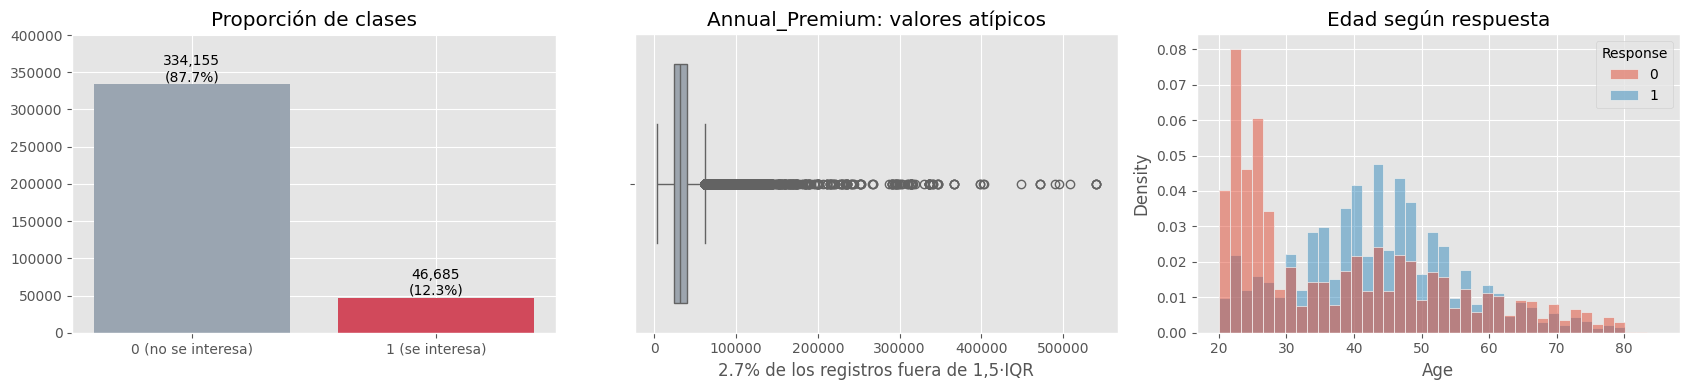

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))

# Gráfico 1: proporción de clases (el desbalance)
conteo = df["Response"].value_counts()
ax[0].bar(["0 (no se interesa)", "1 (se interesa)"], conteo.values, color=["#9aa5b1", "#d1495b"])
for i, v in enumerate(conteo.values):
    ax[0].text(i, v, f"{v:,}\n({v/len(df):.1%})", ha="center", va="bottom")
ax[0].set_ylim(0, conteo.max() * 1.2)
ax[0].set_title("Proporción de clases")

# Gráfico 2: atípicos de Annual_Premium (regla 1,5 · IQR)
q1, q3 = df["Annual_Premium"].quantile([0.25, 0.75])
iqr = q3 - q1
pct_atip = ((df["Annual_Premium"] < q1 - 1.5*iqr) | (df["Annual_Premium"] > q3 + 1.5*iqr)).mean()
sns.boxplot(x=df["Annual_Premium"], ax=ax[1], color="#9aa5b1")
ax[1].set_title("Annual_Premium: valores atípicos")
ax[1].set_xlabel(f"{pct_atip:.1%} de los registros fuera de 1,5·IQR")

# Gráfico 3: edad según la respuesta
sns.histplot(data=df, x="Age", hue="Response", stat="density", common_norm=False, bins=40, ax=ax[2])
ax[2].set_title("Edad según respuesta")

plt.tight_layout()
plt.show()

**Hallazgos 2.2**
- **Desbalance:** 87,7% vs 12,3%. Un modelo que diga "nadie se interesa" acertaría el 87,7% sin aprender nada → no usamos exactitud, usamos **F1 de la clase minoritaria**.
- **Atípicos:** el 2,7% de `Annual_Premium` está fuera de 1,5·IQR. **No se eliminan** (son primas reales); se aplica `log1p` + escalado **dentro del pipeline**, lo que ayuda a SMOTE porque usa distancias.
- **Edad:** los clientes de 20–30 años casi no se interesan; el interés se concentra entre 35 y 55 años.

### 2.3 Interés según variables categóricas

**¿Para qué sirve?**
- Muestra qué variables separan bien a los interesados de los no interesados. Además, contar las categorías de los códigos nos dirá cómo codificarlos en el pipeline.

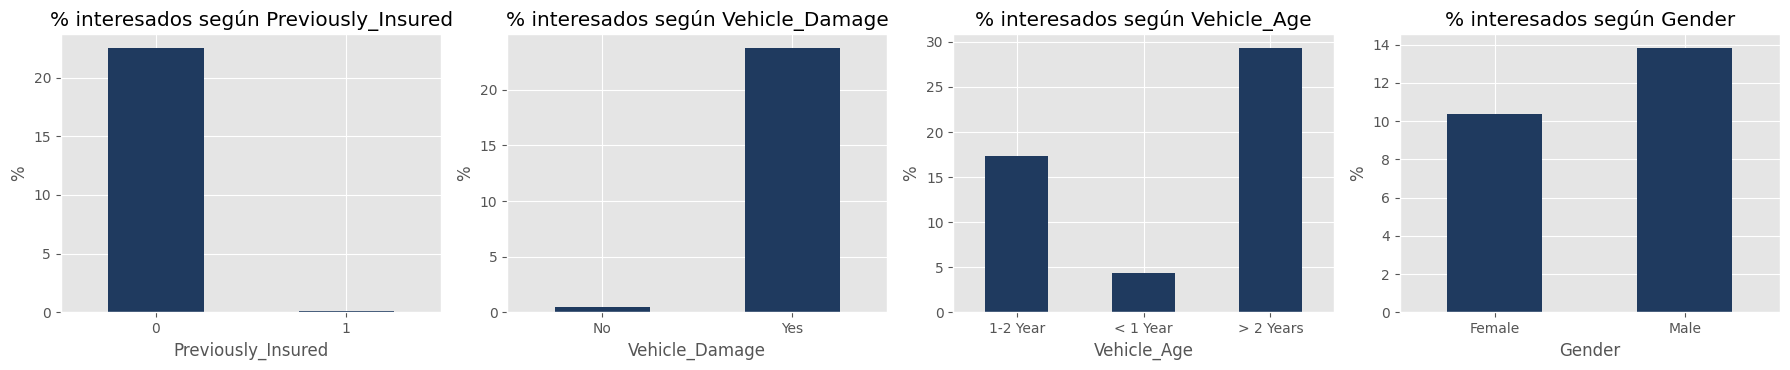

Categorías de Region_Code: 53
Categorías de Policy_Sales_Channel: 155


In [ ]:
# % de clientes interesados (Response = 1) en cada categoría
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
for a, col in zip(ax, ["Previously_Insured", "Vehicle_Damage", "Vehicle_Age", "Gender"]):
    (df.groupby(col)["Response"].mean() * 100).plot.bar(ax=a, color="#1f3a5f", rot=0)
    a.set_title(f"% interesados según {col}")
    a.set_ylabel("%")
plt.tight_layout()
plt.show()

# Cuántas categorías distintas tienen los códigos
print("Categorías de Region_Code:", df["Region_Code"].nunique())
print("Categorías de Policy_Sales_Channel:", df["Policy_Sales_Channel"].nunique())

**Hallazgos 2.3**
- `Previously_Insured` y `Vehicle_Damage` son las variables que más separan: quien ya tiene seguro casi nunca se interesa, y quien tuvo daños se interesa mucho más (~24% vs ~0%).
- `Vehicle_Age` son los vehículos de más de 2 años tienen la mayor tasa de interés (~29%), los de menos de 1 año solo (~4 %).
- `Gender` los hombres se interesan algo más que las mujeres (~14% vs ~10%): se revisará como posible **sesgo** al final.
- `Region_Code` (53 categorías) y `Policy_Sales_Channel` (155) son **códigos, no cantidades**: se codifican con one-hot, agrupando en "otras" las categorías con menos de 1% de los datos.

### 2.4 Partición train / test

**¿Por qué ahora?** Es la regla de oro: primero se separa el test (la bóveda sellada) y después se arma el pipeline. Así, ningún cálculo usa información del test.
- 80% entrenamiento y 20% test, **estratificada** (ambos conjuntos mantienen el 12,26% de interesados) y con semilla fija. **El test se guarda hasta el final**: solo confirma, nunca decide.


In [ ]:
# Separar variables predictoras (X) y objetivo (y)
X = df.drop(columns="Response")
y = df["Response"]

# Partición 80/20 estratificada con semilla fija
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20,
    stratify=y,#Asegura que train y test tengan la misma proporción de interesados
    random_state=SEED)

print(f"Train: {len(X_train):,} filas ({y_train.mean():.2%} interesados)")
print(f"Test:  {len(X_test):,} filas ({y_test.mean():.2%} interesados)")

Train: 304,672 filas (12.26% interesados)
Test:  76,168 filas (12.26% interesados)


### 2.5 Pipeline de preprocesamiento

**Idea**: cada tipo de variable necesita un tratamiento distinto. El 'ColumnTransformer' aplica cada tratamiento a sus columnas y va dentro del pipeline, así que se ajusta solo con el train de cada fold (sin fuga de datos).


| Grupo | Variables | Tratamiento | ¿Por qué? |
|---|---|---|---|
| Numéricas | `Age`, `Vintage` | Imputar mediana → escalar | SMOTE usa distancias: las escalas deben ser comparables |
| N° con atípicos | `Annual_Premium` | Imputar → `log1p` → escalar | Acerca los valores extremos (hallazgo 2.2) |
| Binarias de texto | `Gender`, `Vehicle_Damage` | One-hot (una columna 0/1) | Solo tienen 2 opciones |
| Ordinal | `Vehicle_Age` | `OrdinalEncoder` respetando el orden (<1 < 1-2 < >2 años) | “< 1 año” < “1-2 años” < “> 2 años” |
| Códigos | `Region_Code`, `Policy_Sales_Channel` | One-hot agrupando categorías con menos de 1% | Son códigos, no cantidades (hallazgo 2.3) |
| Ya binarias | `Driving_License`, `Previously_Insured` | Sin cambios | No necesitan nada |

In [ ]:
from sklearn.preprocessing import OrdinalEncoder   # para Vehicle_Age (variable con orden)

# Grupos de columnas según el tratamiento que reciben
num       = ["Age", "Vintage"]
num_log   = ["Annual_Premium"]
bin_texto = ["Gender", "Vehicle_Damage"]
ordinal   = ["Vehicle_Age"]
codigos   = ["Region_Code", "Policy_Sales_Channel"]
pasan     = ["Driving_License", "Previously_Insured"]

ORDEN_VEHICULO = [["< 1 Year", "1-2 Year", "> 2 Years"]]

def make_preprocessor(): #amos a entrenar 10 combinaciones, y cada una necesita su propio preprocesador limpio (si todas compartieran una sola, se pisarian entre sí).
    return ColumnTransformer([
        ("num", SkPipeline([("imp", SimpleImputer(strategy="median")),
                            ("esc", StandardScaler())]), num),
        ("log", SkPipeline([("imp", SimpleImputer(strategy="median")),
                            ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                            ("esc", StandardScaler())]), num_log),
        ("bin", SkPipeline([("imp", SimpleImputer(strategy="most_frequent")),
                            ("oh", OneHotEncoder(drop="if_binary", handle_unknown="ignore",
                                                 sparse_output=False))]), bin_texto),
        ("ord", SkPipeline([("imp", SimpleImputer(strategy="most_frequent")),
                            ("oe", OrdinalEncoder(categories=ORDEN_VEHICULO))]), ordinal),
        ("cod", SkPipeline([("imp", SimpleImputer(strategy="most_frequent")),
                            ("oh", OneHotEncoder(min_frequency=0.01, handle_unknown="infrequent_if_exist",
                                                 sparse_output=False))]), codigos),
        ("pasa", "passthrough", pasan),
    ])

# Prueba: ajustar SOLO con el train y ver cuántas columnas resultan
prep_prueba = make_preprocessor().fit(X_train)
print("Columnas después del preprocesamiento:", len(prep_prueba.get_feature_names_out()))
print(prep_prueba.get_feature_names_out())

Columnas después del preprocesamiento: 44
['num__Age' 'num__Vintage' 'log__Annual_Premium' 'bin__Gender_Male'
 'bin__Vehicle_Damage_Yes' 'ord__Vehicle_Age' 'cod__Region_Code_2.0'
 'cod__Region_Code_3.0' 'cod__Region_Code_6.0' 'cod__Region_Code_8.0'
 'cod__Region_Code_10.0' 'cod__Region_Code_11.0' 'cod__Region_Code_13.0'
 'cod__Region_Code_14.0' 'cod__Region_Code_15.0' 'cod__Region_Code_18.0'
 'cod__Region_Code_21.0' 'cod__Region_Code_28.0' 'cod__Region_Code_29.0'
 'cod__Region_Code_30.0' 'cod__Region_Code_33.0' 'cod__Region_Code_35.0'
 'cod__Region_Code_36.0' 'cod__Region_Code_37.0' 'cod__Region_Code_39.0'
 'cod__Region_Code_41.0' 'cod__Region_Code_45.0' 'cod__Region_Code_46.0'
 'cod__Region_Code_47.0' 'cod__Region_Code_48.0' 'cod__Region_Code_50.0'
 'cod__Region_Code_infrequent_sklearn' 'cod__Policy_Sales_Channel_26.0'
 'cod__Policy_Sales_Channel_122.0' 'cod__Policy_Sales_Channel_124.0'
 'cod__Policy_Sales_Channel_151.0' 'cod__Policy_Sales_Channel_152.0'
 'cod__Policy_Sales_Channel_15

**Hallazgo 2.5: ¿44 columnas son muchas?** No: hay ~6.900 filas de train por columna, lejos del riesgo de sobreajuste. La mayoría viene del one-hot de los códigos, que es lo correcto porque no son cantidades. Agrupar las categorías con menos de 1% redujo los códigos de **208 columnas posibles a 36**.

### 2.6 Diseño de la búsqueda y armado de modelos

**Problema:** con 304.672 filas y 2 CPUs en Colab, buscar hiperparámetros con todo el train tardaría horas.

Por tiempo de cómputo:
- La búsqueda de hiperparámetros usa `RandomizedSearchCV` (10 combinaciones, `StratifiedKFold` de 3 folds, métrica **F1 de la clase minoritaria**) sobre una **submuestra estratificada de 30.000 filas** del train.
- El ganador de cada combinación se **reentrena con todo el train**.
- Cada modelo se arma como `Pipeline` de imblearn: **preprocesador → (SMOTE solo en Etapa A) → modelo**. Así SMOTE se aplica solo a la parte de entrenamiento de cada fold.
- Los pesos de la Etapa B siguen exactamente la tabla del enunciado.

In [ ]:
# Parámetros de la búsqueda (por tiempo de cómputo)
N_SUB, N_ITER, CV_FOLDS = 30_000, 10, 3
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)

# Submuestra estratificada del train (solo para buscar hiperparámetros)
X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size=N_SUB,
                                      stratify=y_train, random_state=SEED)
print(f"Submuestra: {len(X_sub):,} filas ({y_sub.mean():.2%} interesados)")

# scale_pos_weight de XGBoost = negativos / positivos del train
SPW = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {SPW:.3f}")

MODELOS = ["Árbol de decisión", "Random Forest", "XGBoost", "AdaBoost", "LightGBM"]

def base_estimator(nombre, modo): #modo = 'smote' (sin pesos) | 'pesos' (tabla del enunciado) | 'plano' (sin SMOTE ni pesos)
    w = (modo == "pesos")
    if nombre == "Árbol de decisión":
        return DecisionTreeClassifier(class_weight="balanced" if w else None, random_state=SEED)
    if nombre == "Random Forest":
        return RandomForestClassifier(class_weight="balanced" if w else None, random_state=SEED, n_jobs=-1)
    if nombre == "XGBoost":
        return XGBClassifier(scale_pos_weight=SPW if w else 1.0, tree_method="hist",
                             eval_metric="logloss", random_state=SEED, n_jobs=-1)
    if nombre == "AdaBoost":
        return AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1,#fijo, como escrito en el enunciado
                                  class_weight="balanced" if w else None), random_state=SEED)
    if nombre == "LightGBM":
        return LGBMClassifier(class_weight="balanced" if w else None, random_state=SEED,
                              n_jobs=-1, verbose=-1)

def build(nombre, modo): #arma el pipeline completo. Pipeline: preprocesador -> (SMOTE solo en modo 'smote') -> modelo
    pasos = [("prep", make_preprocessor())]
    if modo == "smote":
        pasos.append(("smote", SMOTE(random_state=SEED)))
    pasos.append(("model", base_estimator(nombre, modo)))
    return Pipeline(pasos)

# Grillas de hiperparámetros (al menos 2 por modelo). 'model__' apunta al paso 'model' del pipeline
GRIDS = {
    "Árbol de decisión": {"model__max_depth": [4, 6, 8, 10, 12],
                          "model__min_samples_leaf": [10, 30, 100, 300],
                          "model__criterion": ["gini", "entropy"]},
    "Random Forest":     {"model__n_estimators": [100, 150],
                          "model__max_depth": [8, 12, 16],
                          "model__min_samples_leaf": [5, 20, 50],
                          "model__max_features": ["sqrt", 0.5]},
    "XGBoost":           {"model__n_estimators": [100, 200, 300],
                          "model__max_depth": [3, 5, 7],
                          "model__learning_rate": [0.05, 0.1, 0.2],
                          "model__subsample": [0.8, 1.0]},
    "AdaBoost":          {"model__n_estimators": [50, 100, 200],
                          "model__learning_rate": [0.1, 0.5, 1.0]},
    "LightGBM":          {"model__n_estimators": [100, 200, 300],
                          "model__num_leaves": [15, 31, 63],
                          "model__learning_rate": [0.05, 0.1],
                          "model__min_child_samples": [20, 50, 100]},
}
print("Modelos y grillas listos")

Submuestra: 30,000 filas (12.26% interesados)
scale_pos_weight = 7.158
Modelos y grillas listos


**Comentario**
- Submuestra: 30.000 filas con 12,26 % (mantuvo la proporción).
- scale_pos_weight = 7,158, es decir, hay ~7 negativos por cada positivo.

### 2.7 Función de entrenamiento y evaluación
Esta función hace todo el trabajo de una combinación (modelo + etapa):
- Busca hiperparámetros con validación cruzada en la submuestra.
- Reentrena el ganador con todo el train.
- Calcula las métricas que pide la tabla del enunciado.
- Guarda el avance en Drive (respaldo).

Para cada combinación (modelo + etapa): (1) búsqueda de hiperparámetros con CV en la submuestra, (2) reentrenamiento del ganador con todo el train, (3) métricas pedidas en la tabla del enunciado. **El mejor modelo se elegirá por F1 CV**; el F1 test solo se informa para confirmar.


In [ ]:
# Carpeta en Drive para guardar resultados (si Colab se desconecta, no se pierde nada)
CARPETA = "/content/drive/MyDrive/Certamen1_ML/resultados"
os.makedirs(CARPETA, exist_ok=True)

RESULTADOS = []     # una fila por combinación
MODELOS_FIT = {}    # modelos entrenados y sus mejores hiperparámetros

def correr(nombre, modo):
    etapa = "A (SMOTE)" if modo == "smote" else "B (pesos)"

    # 1) Búsqueda de hiperparámetros con CV estratificada (métrica: F1 de la clase 1)
    t0 = time.time()
    busq = RandomizedSearchCV(build(nombre, modo), GRIDS[nombre], n_iter=N_ITER,
                              scoring="f1", cv=cv, random_state=SEED, n_jobs=1,
                              refit=False)#la búsqueda no reentrena sola porque lo hacemos nosotros con todo el train (la búsqueda usó solo 30.000 filas).
    busq.fit(X_sub, y_sub)
    t_busq = time.time() - t0
    i = busq.best_index_
    folds = [busq.cv_results_[f"split{k}_test_score"][i] for k in range(CV_FOLDS)]

    # 2) Reentrenar el ganador con TODO el train
    modelo = build(nombre, modo).set_params(**busq.best_params_).fit(X_train, y_train)

    # 3) Métricas con umbral 0,5 (el test solo confirma, no decide)
    p_tr = modelo.predict_proba(X_train)[:, 1]
    p_te = modelo.predict_proba(X_test)[:, 1]
    yh_tr, yh_te = (p_tr >= 0.5).astype(int), (p_te >= 0.5).astype(int)

    fila = {"Modelo": nombre, "Etapa": etapa,
            "F1 train": f1_score(y_train, yh_tr),
            "F1 CV": busq.best_score_,
            "F1 CV (std)": busq.cv_results_["std_test_score"][i],
            "F1 test": f1_score(y_test, yh_te),
            "Recall test": recall_score(y_test, yh_te),
            "Precisión test": precision_score(y_test, yh_te),
            "AUC-ROC test": roc_auc_score(y_test, p_te),
            "Tiempo búsqueda (s)": t_busq,
            "Hiperparámetros": {k.replace("model__", ""): v for k, v in busq.best_params_.items()},
            "F1 por fold": folds} #F1 de cada uno de los 3 folds. Sirve para ver la estabilidad: si los 3 valores son parecidos, el modelo es estable.
    fila["Brecha train-test"] = fila["F1 train"] - fila["F1 test"] #si el F1 de train es mucho mayor que el de test, el modelo memorizó (sobreajuste).
    RESULTADOS.append(fila)
    MODELOS_FIT[(nombre, etapa)] = (modelo, busq.best_params_)

    # 4) Guardar avance en Drive
    pd.DataFrame(RESULTADOS).to_csv(f"{CARPETA}/resultados_parciales.csv", index=False)
    print(f"{nombre:18s} {etapa:10s} | F1 CV {fila['F1 CV']:.4f} ± {fila['F1 CV (std)']:.4f} "
          f"| F1 test {fila['F1 test']:.4f} | búsqueda {t_busq:.0f}s")

print("Función lista")

Función lista


## 3. Etapa A: 5 modelos con SMOTE

**¿Qué hace SMOTE?** Toma un cliente interesado, busca otros interesados parecidos y crea clientes “inventados” entre ellos. Así hay más ejemplos de la clase 1 para aprender.

**¿Por qué va dentro del pipeline?** Si aplicáramos SMOTE antes de la validación cruzada, los clientes inventados podrían caer en el fold de validación. El modelo se estaría evaluando con copias casi idénticas de lo que ya vio, lo que es fuga de datos.

- SMOTE va como paso del `Pipeline` de imblearn, **después del preprocesador**. - En cada fold de la validación cruzada se aplica **solo a la parte de entrenamiento**, nunca a la de validación ni al test (así no hay fuga de datos).
- En esta etapa los modelos **no** usan pesos de clase.


In [ ]:
# Etapa A: los 5 modelos con SMOTE dentro del pipeline
t_inicio = time.time()
for m in MODELOS:
    correr(m, "smote")
print(f"\nEtapa A terminada en {(time.time() - t_inicio)/60:.1f} minutos")

Árbol de decisión  A (SMOTE)  | F1 CV 0.4337 ± 0.0024 | F1 test 0.4274 | búsqueda 21s
Random Forest      A (SMOTE)  | F1 CV 0.4457 ± 0.0055 | F1 test 0.4412 | búsqueda 218s
XGBoost            A (SMOTE)  | F1 CV 0.4399 ± 0.0084 | F1 test 0.4412 | búsqueda 48s
AdaBoost           A (SMOTE)  | F1 CV 0.4318 ± 0.0041 | F1 test 0.4200 | búsqueda 156s
LightGBM           A (SMOTE)  | F1 CV 0.4351 ± 0.0098 | F1 test 0.4448 | búsqueda 41s

Etapa A terminada en 20.6 minutos


**Tres cosas buenas:**

- El F1 CV y el F1 test se parecen mucho en todos los modelos, así que no hay sobreajuste grave. Lo que el modelo aprendió en la validación cruzada se repite en datos nuevos.
- La desviación (±) es pequeña (entre 0,002 y 0,010), así que los modelos son estables entre folds.
- Los ensambles le ganan al árbol solo (excepto AdaBoost): combinar muchos árboles mejora el resultado.

**¿Por qué el F1 es “solo” ~0,44?** Porque se mide con el umbral 0,5 y el problema es difícil: los interesados se parecen mucho a los no interesados. Luego veremos que lo que importa es el costo en dinero, no el F1.

## 4. Etapa B: 5 modelos con pesos ponderados
Sin SMOTE. Cada modelo le da **más peso** a los errores en la clase minoritaria, según la tabla del enunciado:

| Modelo | Cómo se aplican los pesos |
|---|---|
| Árbol de decisión | `class_weight="balanced"` |
| Random Forest | `class_weight="balanced"` |
| XGBoost | `scale_pos_weight` = negativos / positivos del train (≈ 7,16) |
| AdaBoost | Árbol base `DecisionTreeClassifier(max_depth=1, class_weight="balanced")` |
| LightGBM | `class_weight="balanced"` |

**¿Qué hace class_weight="balanced"?** Le dice al modelo: “equivocarte con un interesado cuesta ~7 veces más que equivocarte con un no interesado”. Así el modelo presta más atención a la clase rara, sin inventar datos.

In [ ]:
# Etapa B: los mismos 5 modelos, sin SMOTE, con pesos para la clase minoritaria
t_inicio = time.time()
for m in MODELOS:
    correr(m, "pesos")
print(f"\nEtapa B terminada en {(time.time() - t_inicio)/60:.1f} minutos")

Árbol de decisión  B (pesos)  | F1 CV 0.4289 ± 0.0054 | F1 test 0.4274 | búsqueda 6s
Random Forest      B (pesos)  | F1 CV 0.4413 ± 0.0037 | F1 test 0.4331 | búsqueda 89s
XGBoost            B (pesos)  | F1 CV 0.4352 ± 0.0050 | F1 test 0.4348 | búsqueda 25s
AdaBoost           B (pesos)  | F1 CV 0.3767 ± 0.0057 | F1 test 0.3823 | búsqueda 32s
LightGBM           B (pesos)  | F1 CV 0.4337 ± 0.0042 | F1 test 0.4342 | búsqueda 18s

Etapa B terminada en 5.8 minutos


**Hallazgo 1:** con SMOTE el F1 CV es levemente mayor en los 5 modelos; la diferencia es pequeña (entre 0,001 y 0,005), salvo en AdaBoost (0,055). En cambio, los pesos son ~3 veces más rápidos.

**Hallazgo 2 (importante):** AdaBoost con pesos cae a 0,3767. No es un error. Pasa porque AdaBoost ya repondera los datos por sí solo: en cada ronda le da más peso a los clientes mal clasificados. Si encima le sumamos class_weight="balanced", los interesados quedan con doble peso. El modelo empieza a decir “sí” a demasiada gente y la precisión se cae. Además, su árbol base es de profundidad 1 (cada árbol es muy simple).

Se nota en la tabla: AdaBoost con pesos tiene el **recall más alto (0,978)** pero la **precisión más baja (0,238)**: marca como interesados a casi todos.

## 5. Tabla de las 10 combinaciones y mejor modelo por CV
Ordenamos por **F1 CV** (criterio de selección). El F1 test solo confirma.

In [ ]:
# Tabla comparativa de las 10 combinaciones, ordenada por F1 CV
res = pd.DataFrame(RESULTADOS)
cols = ["Modelo", "Etapa", "F1 train", "F1 CV", "F1 CV (std)", "F1 test", "Brecha train-test",
        "Recall test", "Precisión test", "AUC-ROC test", "Tiempo búsqueda (s)"]
tabla = res[cols].sort_values("F1 CV", ascending=False).reset_index(drop=True)
tabla.to_csv(f"{CARPETA}/tabla_10_combinaciones.csv", index=False)

(tabla.style
      .format({c: "{:.4f}" for c in cols[2:10]} | {"Tiempo búsqueda (s)": "{:.0f}"})
      .background_gradient(subset=["F1 CV"], cmap="Blues")
      .hide(axis="index"))

Modelo,Etapa,F1 train,F1 CV,F1 CV (std),F1 test,Brecha train-test,Recall test,Precisión test,AUC-ROC test,Tiempo búsqueda (s)
Random Forest,A (SMOTE),0.4538,0.4457,0.0055,0.4412,0.0126,0.8276,0.3008,0.8484,218
Random Forest,B (pesos),0.4432,0.4413,0.0037,0.4331,0.0100,0.9181,0.2834,0.8543,89
XGBoost,A (SMOTE),0.4444,0.4399,0.0084,0.4412,0.0033,0.8679,0.2958,0.8512,48
XGBoost,B (pesos),0.4461,0.4352,0.0050,0.4348,0.0113,0.9175,0.2849,0.8559,25
LightGBM,A (SMOTE),0.4473,0.4351,0.0098,0.4448,0.0025,0.8259,0.3043,0.8502,41
LightGBM,B (pesos),0.4437,0.4337,0.0042,0.4342,0.0096,0.9209,0.2841,0.8555,18
Árbol de decisión,A (SMOTE),0.4281,0.4337,0.0024,0.4274,0.0007,0.8857,0.2817,0.8409,21
AdaBoost,A (SMOTE),0.4217,0.4318,0.0041,0.4200,0.0017,0.9331,0.2710,0.8476,156
Árbol de decisión,B (pesos),0.4301,0.4289,0.0054,0.4274,0.0027,0.9282,0.2776,0.8482,6
AdaBoost,B (pesos),0.3826,0.3767,0.0057,0.3823,0.0003,0.9782,0.2376,0.7883,32


In [ ]:
# Mejor modelo: se elige SOLO por F1 CV (el test no participa en la decisión)
mejor = res.sort_values("F1 CV", ascending=False).iloc[0]
MEJOR_NOMBRE, MEJOR_ETAPA = mejor["Modelo"], mejor["Etapa"]

print(f"MEJOR POR CV: {MEJOR_NOMBRE} · Etapa {MEJOR_ETAPA}")
print(f"  F1 CV   = {mejor['F1 CV']:.4f} ± {mejor['F1 CV (std)']:.4f}")
print(f"  F1 test = {mejor['F1 test']:.4f}  (confirma)")
print(f"  Brecha train-test = {mejor['Brecha train-test']:.4f}")
print(f"  Hiperparámetros: {mejor['Hiperparámetros']}")

# SMOTE vs pesos: promedio de cada métrica por etapa
print("\nPromedio por etapa:")
res.groupby("Etapa")[["F1 CV", "F1 test", "Recall test", "Precisión test",
                      "Brecha train-test", "Tiempo búsqueda (s)"]].mean().round(4)

MEJOR POR CV: Random Forest · Etapa A (SMOTE)
  F1 CV   = 0.4457 ± 0.0055
  F1 test = 0.4412  (confirma)
  Brecha train-test = 0.0126
  Hiperparámetros: {'n_estimators': 150, 'min_samples_leaf': 20, 'max_features': 0.5, 'max_depth': 16}

Promedio por etapa:


,F1 CV,F1 test,Recall test,Precisión test,Brecha train-test,Tiempo búsqueda (s)
Etapa,,,,,,
A (SMOTE),0.4372,0.4349,0.8680,0.2907,0.0042,96.7748
B (pesos),0.4232,0.4224,0.9326,0.2735,0.0068,33.9226


- Random Forest gana en ambas etapas (1º y 2º lugar).
¿Es un empate? La diferencia entre RF+SMOTE (0,4457) y RF+pesos (0,4413) es 0,0044, que es menor que la desviación entre folds (±0,0055).
- Sobreajuste: la brecha train-test del ganador es 0,0126, que es baja. - max_depth=16 con min_samples_leaf=20 evita que memorice.
- SMOTE vs pesos (promedios):
SMOTE tiene más F1 (0,437 vs 0,423) y más precisión.
Pesos tiene más recall (0,93 vs 0,87), porque detecta más interesados pero con más falsas alarmas.
Pesos es 3 veces más rápido (34 s vs 97 s).

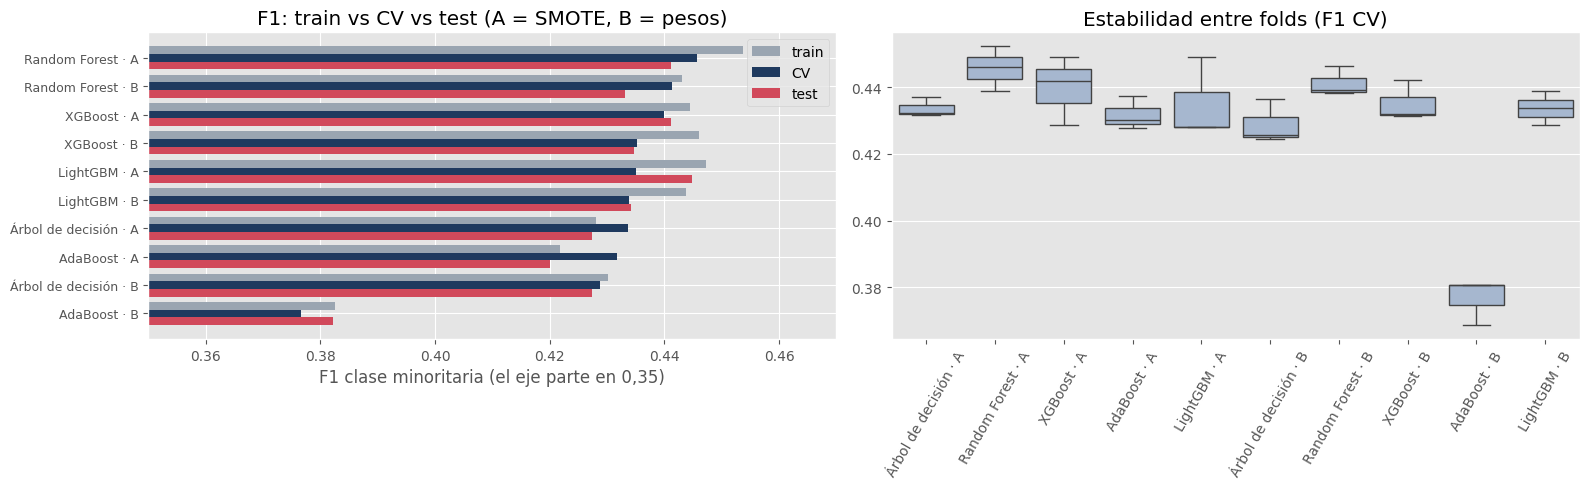

In [ ]:
##Gráfico Comparativo
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

# Izquierda: F1 en train, CV y test (la distancia train-test muestra el sobreajuste)
r = res.assign(Comb=res["Modelo"] + " · " + res["Etapa"].str[0]).sort_values("F1 CV")
y_pos, h = np.arange(len(r)), 0.27
ax[0].barh(y_pos + h, r["F1 train"], h, label="train", color="#9aa5b1")
ax[0].barh(y_pos,     r["F1 CV"],    h, label="CV",    color="#1f3a5f")
ax[0].barh(y_pos - h, r["F1 test"],  h, label="test",  color="#d1495b")
ax[0].set_yticks(y_pos); ax[0].set_yticklabels(r["Comb"], fontsize=9)
ax[0].set_xlim(0.35, 0.47)
ax[0].set_xlabel("F1 clase minoritaria (el eje parte en 0,35)")
ax[0].set_title("F1: train vs CV vs test (A = SMOTE, B = pesos)")
ax[0].legend()

# Derecha: F1 de cada fold (cajas angostas = modelo estable)
folds_df = pd.DataFrame({f"{m} · {e[0]}": f for m, e, f in
                         zip(res["Modelo"], res["Etapa"], res["F1 por fold"])})
sns.boxplot(data=folds_df, ax=ax[1], color="#9fb6d6")
ax[1].tick_params(axis="x", rotation=60)
ax[1].set_title("Estabilidad entre folds (F1 CV)")

plt.tight_layout()
plt.savefig(f"{CARPETA}/comparacion_10.png", dpi=130)
plt.show()

**Justificación del mejor modelo**
- **Ganador por F1 CV: Random Forest con SMOTE (Etapa A)**: F1 CV = 0,4457 ± 0,0055. El F1 test (0,4412) confirma el resultado.
- **Empate técnico:** el segundo lugar (Random Forest con pesos, 0,4413) está a solo 0,0044, menos que la desviación entre folds. Ambas versiones de Random Forest son prácticamente equivalentes; se elige la de mayor F1 CV según la regla del enunciado.
- **Sobreajuste:** brecha train–test de 0,0126, baja. Los hiperparámetros (`max_depth=16`, `min_samples_leaf=20`) limitan que el bosque memorice.
- **Estabilidad:** desviación entre folds baja (±0,0055); el boxplot no muestra folds anómalos.
- **¿Por qué gana Random Forest?** Es *bagging*: promedia 150 árboles entrenados con muestras y variables distintas, lo que **reduce la varianza** de un árbol solo (árbol: 0,4337 → bosque: 0,4457).
- **SMOTE vs pesos:** SMOTE logra algo más de F1 y precisión (0,437 vs 0,423 en promedio), mientras que los pesos dan más recall (0,93 vs 0,87) y son **3 veces más rápidos**. En esta base la diferencia de F1 es pequeña, así que **los pesos serían preferibles si el tiempo de cómputo importa**, porque no fabrican datos sintéticos.
- **AdaBoost con pesos (0,3767)** es el peor: AdaBoost ya repondera los casos mal clasificados en cada ronda, y sumarle `class_weight="balanced"` duplica el énfasis en la clase 1, lo que baja mucho la precisión.
- Ambas estrategias **inflan** la probabilidad de la clase minoritaria; por eso en la Parte 2 el mejor modelo se reentrena con la proporción real.
- **Limitación de SMOTE:** SMOTE crea clientes "inventados" interpolando entre vecinos **después del one-hot**, por lo que genera valores intermedios (por ejemplo, 0,37 en la columna de una región) que no existen en la realidad. La variante **SMOTENC** (para variables categóricas) lo evitaría. Mantenemos SMOTE porque es lo que pide el enunciado, y el efecto es acotado: los árboles cortan cada variable en un umbral, así que un 0,37 simplemente cae a un lado del corte. Además, la Etapa B (pesos), que no fabrica datos, obtiene un F1 equivalente.

## 6. Matriz de costos en dinero

Se buscaron fuentes reales para justificar los costos:
- **Fuente FP:** [Fullview / CX Today](https://www.fullview.io/blog/calculate-cost-per-inbound-and-outbound-call)
- **Fuente FN:** [Sonant](https://www.sonant.ai/blog/commission-per-policy)

| Error | Qué significa | Costo Estimado | Justificación |
| :--- | :--- | :---: | :--- |
| **FP** | Llamamos a alguien que no compra | US\$ 5 | Costo promedio de una llamada de call center (US\$ 2,70 - US\$ 5,60 ). Usamos el extremo alto. |
| **FN** | No llamamos a alguien que sí compraría | US\$ 50 | Margen perdido de la venta: comisión típica de 10–12% de la prima de un seguro de auto. Con una prima de ~500 US\$/año → ~50 US\$/año. *Supuesto conservador.* |
| TP / TN | Decisión correcta | 0 | No hay error |

(*Supuesto conservador FN* Es conservador, porque en EE. UU. las primas son más altas (~US\$ 1.500 → US\$ 150–180).)
- Razón **FN / FP = 10**: perder una venta cuesta 10 veces más que una llamada inútil.
- **Costo total** = FP · C_FP + FN · C_FN
- **Umbral teórico** (Elkan, 2001): contactar si P(1 | x) ≥ p* = C_FP / (C_FP + C_FN)
- Los montos son **supuestos apoyados en fuentes**; luego vemos qué pasa si la razón cambia.

In [ ]:
# Costos del negocio (US$ por cliente)
C_FP, C_FN = 5.0, 50.0

# Umbral teórico (Elkan, 2001): contactar si P(1|x) >= C_FP / (C_FP + C_FN)
P_STAR = C_FP / (C_FP + C_FN)
print(f"p* = {C_FP:.0f} / ({C_FP:.0f} + {C_FN:.0f}) = {P_STAR:.4f}")

def costo_total(y_real, y_pred, c_fp=C_FP, c_fn=C_FN):
    #Costo en dinero = (n° de FP) x C_FP + (n° de FN) x C_FN
    tn, fp, fn, tp = confusion_matrix(y_real, y_pred, labels=[0, 1]).ravel()
    return fp * c_fp + fn * c_fn

def evaluar(y_real, y_pred, nombre):
    #Resume una estrategia: matriz de confusión, recall, precisión y costos
    tn, fp, fn, tp = confusion_matrix(y_real, y_pred, labels=[0, 1]).ravel()
    return {"Estrategia": nombre, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "Recall": tp / (tp + fn) if (tp + fn) else 0.0,
            "Precisión": tp / (tp + fp) if (tp + fp) else 0.0,
            "Costo FP": fp * C_FP, "Costo FN": fn * C_FN,
            "Costo total": fp * C_FP + fn * C_FN}
print("Funciones de costo listas")

p* = 5 / (5 + 50) = 0.0909
Funciones de costo listas


### 6.1 ¿De dónde sale p*? Costo esperado de cada decisión
Para un cliente con probabilidad **p** de comprar hay dos decisiones:

| Decisión | Me equivoco si… | Costo esperado |
|---|---|---|
| **No llamar** | el cliente sí compraba (FN) | p · C_FN = p · 50 |
| **Llamar** | el cliente no compra (FP) | (1 − p) · C_FP = (1 − p) · 5 |

Conviene llamar cuando llamar cuesta menos en promedio:

(1 − p) · C_FP ≤ p · C_FN  ⟺  **p ≥ C_FP / (C_FP + C_FN) = 5/55 = 0,091**

-> Es decir, conviene llamar a cualquier cliente con al menos 9 % de probabilidad, no solo a los de más de 50 %.

**Ejemplo:** un cliente con p = 0,15. No llamarlo cuesta 0,15 · 50 = **7,5**; llamarlo cuesta 0,85 · 5 = **4,25**. **Se llama**, aunque su probabilidad sea mucho menor que 0,5. El umbral 0,5 solo es óptimo cuando C_FP = C_FN.

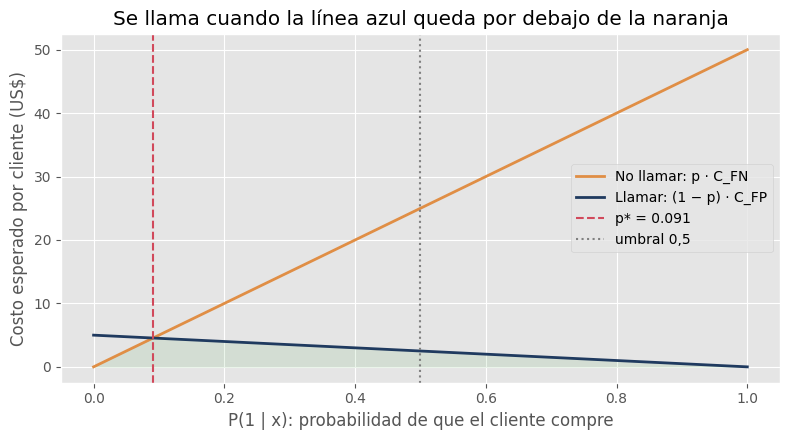

In [ ]:
# Costo esperado por cliente de cada decisión, según su probabilidad p
p = np.linspace(0, 1, 201)
plt.figure(figsize=(8, 4.5))
plt.plot(p, p * C_FN, label="No llamar: p · C_FN", color="#e08e45", lw=2)
plt.plot(p, (1 - p) * C_FP, label="Llamar: (1 − p) · C_FP", color="#1f3a5f", lw=2)
plt.axvline(P_STAR, ls="--", color="#d1495b", label=f"p* = {P_STAR:.3f}")
plt.axvline(0.5, ls=":", color="gray", label="umbral 0,5")
plt.fill_between(p, 0, np.minimum(p * C_FN, (1 - p) * C_FP), color="green", alpha=0.08)
plt.xlabel("P(1 | x): probabilidad de que el cliente compre")
plt.ylabel("Costo esperado por cliente (US$)")
plt.title("Se llama cuando la línea azul queda por debajo de la naranja")
plt.legend()
plt.tight_layout()
plt.savefig(f"{CARPETA}/derivacion_pstar.png", dpi=130)
plt.show()

**¿Cómo leer el gráfico?** Las dos líneas se cruzan exactamente en p = 0,091. A la derecha del cruce, llamar es más barato. El umbral 0,5 queda muy a la derecha: con él dejaríamos de llamar a muchos clientes que convenía llamar.

## 7. Umbral teórico, empírico y ahorro (comparación en test)

**Idea clave**: SMOTE infla la probabilidad de compra porque el modelo aprendió con 50 % de interesados, cuando en la realidad hay 12 %. Si además bajamos el umbral a 0,091, estaríamos corrigiendo el desbalance dos veces. Por eso el mejor modelo se **reentrena con la proporción real** (sin SMOTE ni pesos) y con sus **mismos hiperparámetros**.

**Umbral empírico.** `TunedThresholdClassifierCV` prueba muchos umbrales con validación cruzada **solo sobre el train** y elige el que minimiza el costo en dinero.

In [ ]:
# 1) Mismo modelo y mismos hiperparámetros, pero SIN SMOTE ni pesos (proporción real)
_, mejores_params = MODELOS_FIT[(MEJOR_NOMBRE, MEJOR_ETAPA)]
modelo_real = build(MEJOR_NOMBRE, "plano").set_params(**mejores_params)
print("Modelo en escala real:", [paso for paso, _ in modelo_real.steps])   # no debe aparecer 'smote'

# 2) Umbral empírico: el que minimiza el costo con CV, usando SOLO el train
scorer_costo = make_scorer(costo_total, greater_is_better=False)
t0 = time.time()
tuned = TunedThresholdClassifierCV(modelo_real, scoring=scorer_costo,
                                   thresholds=np.linspace(0.01, 0.99, 197),
                                   cv=cv, refit=True, random_state=SEED)
tuned.fit(X_train, y_train)
print(f"Tiempo: {(time.time() - t0)/60:.1f} min")

U_EMP = float(tuned.best_threshold_)
modelo_final = tuned.estimator_        # Random Forest reentrenado con todo el train, escala real
print(f"Umbral teórico  p* = {P_STAR:.4f}")
print(f"Umbral empírico    = {U_EMP:.4f}")

Modelo en escala real: ['prep', 'model']
Tiempo: 8.5 min
Umbral teórico  p* = 0.0909
Umbral empírico    = 0.0900


**Son casi idénticos (0,0909 vs 0,0900).** Esto indica que las probabilidades del modelo en escala real están **bien calibradas en la zona del umbral**: la regla teórica de Elkan funciona sobre ellas. Es lo mismo que pasó en el caso de clase (0,167 vs 0,171) y confirma que reentrenar sin SMOTE fue correcto.

In [ ]:
# Guardar el modelo final en Drive (si Colab se desconecta, no hay que reentrenar 14 min)
joblib.dump(modelo_final, f"{CARPETA}/mejor_modelo.joblib", compress=3)
joblib.dump({"modelo": MEJOR_NOMBRE, "etapa": MEJOR_ETAPA, "hiperparametros": mejores_params,
             "umbral_teorico": P_STAR, "umbral_empirico": U_EMP, "C_FP": C_FP, "C_FN": C_FN},
            f"{CARPETA}/metadata.joblib")
print("Modelo guardado en Drive")

Modelo guardado en Drive


### 7.1 Comparación de estrategias en test
Recién ahora usamos el test. Comparamos el costo total en dinero de 5 estrategias, más "llamar a todos" como referencia extra.

In [ ]:
# Probabilidades en escala real sobre el test
proba_test = modelo_final.predict_proba(X_test)[:, 1]
y_te = y_test.to_numpy()

# Modelo con pesos de la Etapa B (mismo algoritmo), con umbral 0,5
mod_B, _ = MODELOS_FIT[(MEJOR_NOMBRE, "B (pesos)")]
proba_pesos = mod_B.predict_proba(X_test)[:, 1]

estrategias = [
    ("No hacer nada (todo 0)",            np.zeros_like(y_te)),
    ("Llamar a todos (todo 1)",           np.ones_like(y_te)),
    ("Umbral 0,5",                        (proba_test >= 0.5).astype(int)),
    (f"Umbral teórico p* = {P_STAR:.3f}", (proba_test >= P_STAR).astype(int)),
    (f"Umbral empírico = {U_EMP:.3f}",    (proba_test >= U_EMP).astype(int)),
    ("Modelo con pesos (Etapa B, 0,5)",   (proba_pesos >= 0.5).astype(int)),
]
comp = pd.DataFrame([evaluar(y_te, yh, n) for n, yh in estrategias])

# Ahorro frente al umbral 0,5
costo_05 = comp.loc[comp["Estrategia"] == "Umbral 0,5", "Costo total"].iloc[0]
comp["Ahorro vs 0,5"] = costo_05 - comp["Costo total"]
comp["Ahorro %"] = comp["Ahorro vs 0,5"] / costo_05
comp.to_csv(f"{CARPETA}/comparacion_umbrales_test.csv", index=False)

(comp.style
     .format({"Recall": "{:.3f}", "Precisión": "{:.3f}", "Costo FP": "${:,.0f}", "Costo FN": "${:,.0f}",
              "Costo total": "${:,.0f}", "Ahorro vs 0,5": "${:,.0f}", "Ahorro %": "{:.1%}",
              "TN": "{:,}", "FP": "{:,}", "FN": "{:,}", "TP": "{:,}"})
     .highlight_min(subset=["Costo total"], color="#c8e6c9")
     .hide(axis="index"))

Estrategia,TN,FP,FN,TP,Recall,Precisión,Costo FP,Costo FN,Costo total,"Ahorro vs 0,5",Ahorro %
No hacer nada (todo 0),"66,831",0,"9,337",0,0.000,0.000,$0,"$466,850","$466,850","$-4,520",-1.0%
Llamar a todos (todo 1),0,"66,831",0,"9,337",1.000,0.123,"$334,155",$0,"$334,155","$128,175",27.7%
"Umbral 0,5","66,735",96,"9,237",100,0.011,0.510,$480,"$461,850","$462,330",$0,0.0%
Umbral teórico p* = 0.091,"42,217","24,614",381,"8,956",0.959,0.267,"$123,070","$19,050","$142,120","$320,210",69.3%
Umbral empírico = 0.090,"42,138","24,693",373,"8,964",0.960,0.266,"$123,465","$18,650","$142,115","$320,215",69.3%
"Modelo con pesos (Etapa B, 0,5)","45,159","21,672",765,"8,572",0.918,0.283,"$108,360","$38,250","$146,610","$315,720",68.3%


**¿Por qué comparamos contra “Modelo con pesos (Etapa B)”?:** Según el enunciado, sirve para ver si “balancear con pesos y dejar el umbral en 0,5” es tan bueno como “modelo real + umbral óptimo”. Son dos caminos distintos para el mismo objetivo.

**Lectura de resultados (test: 76.168 clientes, C_FP = US\$5, C_FN = US\$50)**
- Con el **umbral 0,5** el modelo casi no llama a nadie (recall 1,1%): cuesta US\$462.330, prácticamente lo mismo que **no hacer nada** (US\$466.850).
- El **umbral empírico (0,090)** baja el costo a **US\$142.115**: un **ahorro de US\$320.215 (69,3%)** frente al umbral 0,5. Detecta al 96% de los interesados a cambio de más llamadas inútiles, que son baratas.
- El **umbral teórico (0,091)** da casi el mismo costo (US\$142.120): las probabilidades en escala real están **bien calibradas**.
- El **modelo con pesos (Etapa B) a 0,5** cuesta US\$146.610: se acerca, pero queda ~US\$4.500 sobre el óptimo, porque los pesos no usan los costos reales del negocio.
- **Llamar a todos** (US\$334.155) es mejor que no hacer nada, pero el umbral óptimo lo mejora en un 57%.

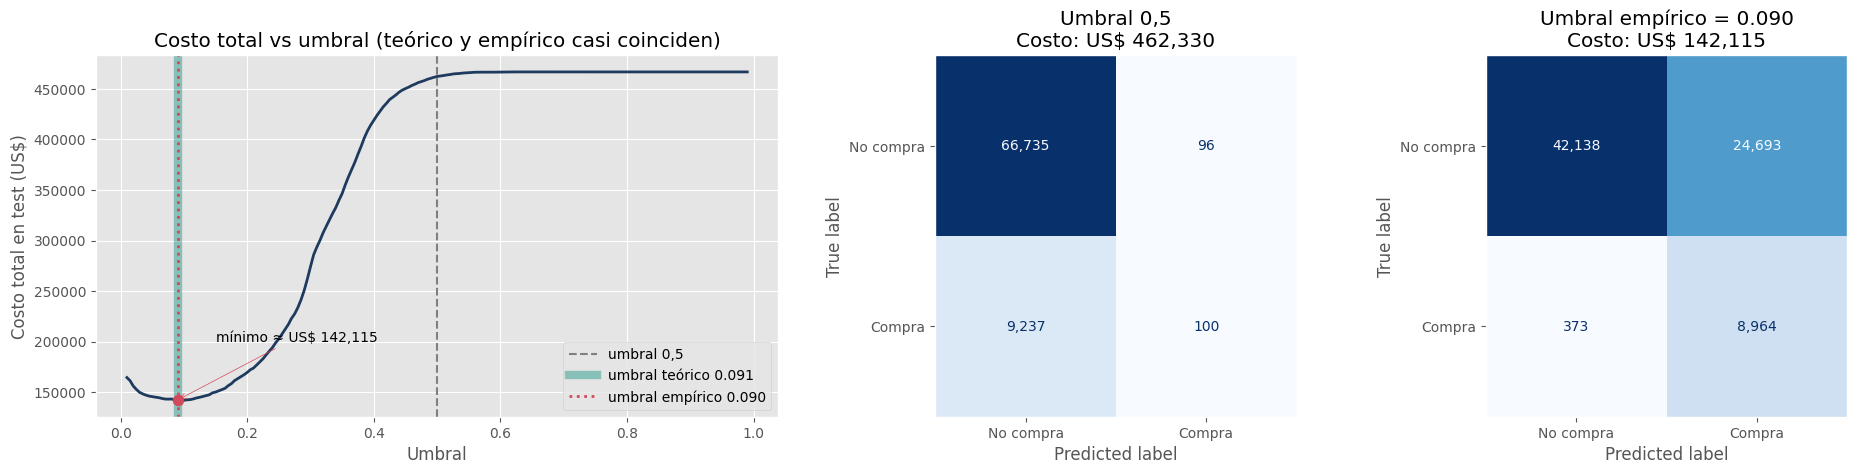

In [ ]:
# Curva de costo total vs umbral (test) + matrices de confusión de 0,5 y del empírico
umbrales = np.linspace(0.01, 0.99, 197)
costos = [costo_total(y_te, (proba_test >= t).astype(int)) for t in umbrales]

fig, ax = plt.subplots(1, 3, figsize=(19, 4.8), gridspec_kw={"width_ratios": [1.6, 1, 1]})

ax[0].plot(umbrales, costos, color="#1f3a5f", lw=2)
# Teórico: línea gruesa verde (abajo). Empírico: línea delgada roja punteada (encima).
ax[0].axvline(0.5, color="gray", ls="--", lw=1.5, label="umbral 0,5")
ax[0].axvline(P_STAR, color="#2a9d8f", ls="-", lw=6, alpha=0.5, label=f"umbral teórico {P_STAR:.3f}")
ax[0].axvline(U_EMP, color="#d1495b", ls=":", lw=2, label=f"umbral empírico {U_EMP:.3f}")
# Punto de costo mínimo, con su valor
ax[0].scatter(U_EMP, costo_total(y_te, (proba_test >= U_EMP).astype(int)), color="#d1495b", s=60, zorder=3)
ax[0].annotate(f"mínimo ≈ US$ {costo_total(y_te, (proba_test >= U_EMP).astype(int)):,.0f}",
               xy=(U_EMP, costo_total(y_te, (proba_test >= U_EMP).astype(int))),
               xytext=(0.15, 200000), arrowprops=dict(arrowstyle="->", color="#d1495b"))
ax[0].set_xlabel("Umbral"); ax[0].set_ylabel("Costo total en test (US$)")
ax[0].set_title("Costo total vs umbral (teórico y empírico casi coinciden)"); ax[0].legend()

for a, (nombre, yh) in zip(ax[1:], [estrategias[2], estrategias[4]]):
    ConfusionMatrixDisplay(confusion_matrix(y_te, yh), display_labels=["No compra", "Compra"]
                           ).plot(ax=a, cmap="Blues", colorbar=False, values_format=",")
    a.set_title(f"{nombre}\nCosto: US$ {costo_total(y_te, yh):,.0f}")
    a.grid(False)

plt.tight_layout()
plt.savefig(f"{CARPETA}/costo_vs_umbral.png", dpi=130)
plt.show()

**Lectura del gráfico:** el costo es mínimo cerca de 0,09 (~US\$ 142 mil). Desde ahí sube rápido y, pasado 0,5, queda plano en ~US\$ 466 mil, igual que no hacer nada. Con el **umbral 0,5** se pierden **9.237 ventas**; con el **umbral empírico** solo **373**, a cambio de 24.693 llamadas inútiles, que son baratas (US\$ 5 cada una).

### 7.2 Curva ROC y recta de iso-costo
Cada punto de la ROC es un umbral distinto del **mismo** modelo. Con P positivos y N negativos:

Costo = C_FN · P · (1 − TPR) + C_FP · N · FPR

Los puntos de igual costo forman rectas de pendiente **m = (C_FP · N) / (C_FN · P)**. El umbral óptimo es donde la recta de iso-costo **toca** la ROC más arriba y a la izquierda.

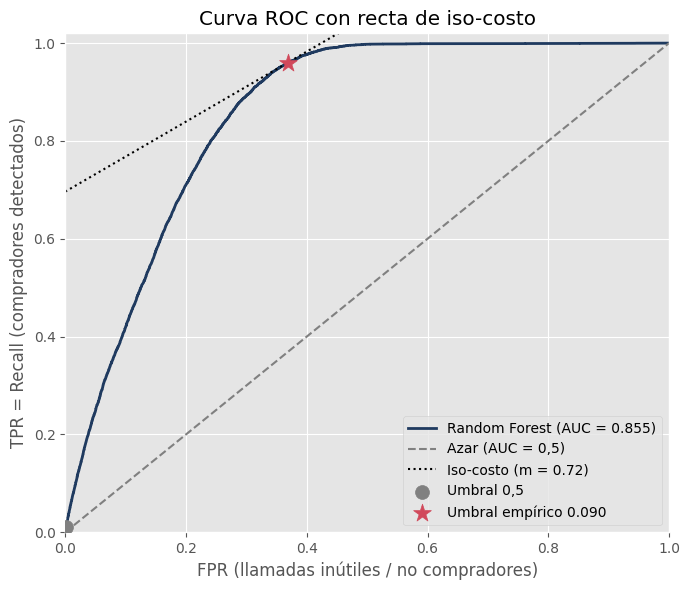

Pendiente iso-costo m = (5·66,831) / (50·9,337) = 0.72


In [ ]:
fpr, tpr, _ = roc_curve(y_te, proba_test)
P, N = (y_te == 1).sum(), (y_te == 0).sum()
m = (C_FP * N) / (C_FN * P)                               # pendiente de la recta de iso-costo
k = np.argmin(C_FN * P * (1 - tpr) + C_FP * N * fpr)      # punto de mínimo costo en la ROC

def punto(y_pred):
    """(FPR, TPR) de una decisión concreta"""
    tn, fp, fn, tp = confusion_matrix(y_te, y_pred).ravel()
    return fp / (fp + tn), tp / (tp + fn)

xs = np.linspace(0, 1, 50)
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color="#1f3a5f", lw=2, label=f"Random Forest (AUC = {roc_auc_score(y_te, proba_test):.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Azar (AUC = 0,5)")
plt.plot(xs, tpr[k] + m * (xs - fpr[k]), ":", color="black", label=f"Iso-costo (m = {m:.2f})")
plt.scatter(*punto((proba_test >= 0.5).astype(int)), s=100, color="gray", zorder=3, label="Umbral 0,5")
plt.scatter(*punto((proba_test >= U_EMP).astype(int)), s=180, marker="*", color="#d1495b",
            zorder=3, label=f"Umbral empírico {U_EMP:.3f}")
plt.xlim(0, 1); plt.ylim(0, 1.02)
plt.xlabel("FPR (llamadas inútiles / no compradores)")
plt.ylabel("TPR = Recall (compradores detectados)")
plt.title("Curva ROC con recta de iso-costo")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{CARPETA}/roc_isocosto.png", dpi=130)
plt.show()
print(f"Pendiente iso-costo m = ({C_FP:.0f}·{N:,}) / ({C_FN:.0f}·{P:,}) = {m:.2f}")

**Lectura ROC:** AUC = 0,855 (el modelo ordena bien a los clientes: un comprador al azar recibe mayor probabilidad que un no comprador el 85,5% de las veces). El **umbral 0,5** queda abajo a la izquierda (casi no llama ni detecta). El **umbral empírico** queda donde la recta de iso-costo (pendiente m = 0,72) **toca** la curva: es el punto de mínimo costo, tal como se vio en clases.

### 7.3 Ahorro a escala y revisión de sesgos
**¿Qué buscamos?**
- “% llamados” vs “% interesados reales”: si un grupo recibe muchas menos llamadas, hay que ver si es porque de verdad se interesa menos (justo) o porque el modelo lo discrimina (injusto).
- Recall por grupo: si en un grupo baja mucho, el modelo “abandona” a esos clientes.

In [ ]:
# Ahorro por cliente (test) llevado a carteras más grandes
ahorro_cliente = comp.loc[comp["Estrategia"].str.startswith("Umbral empírico"), "Ahorro vs 0,5"].iloc[0] / len(y_te)
print(f"Ahorro por cliente: US$ {ahorro_cliente:.2f}")
for cartera in [100_000, 1_000_000]:
    print(f"Cartera de {cartera:>9,} clientes → ahorro estimado US$ {ahorro_cliente * cartera:,.0f}")

# ¿El modelo trata distinto a algún grupo? (umbral empírico)
y_emp = (proba_test >= U_EMP).astype(int)
aux = pd.DataFrame({"y": y_te, "pred": y_emp,
                    "Gender": X_test["Gender"].values,
                    "Edad": pd.cut(X_test["Age"].values, [0, 30, 45, 60, 100],
                                   labels=["<30", "30-44", "45-59", "60+"])})

def resumen(g):
    return pd.Series({"Clientes": len(g),
                      "% llamados": g["pred"].mean(),
                      "% interesados reales": g["y"].mean(),
                      "Recall": recall_score(g["y"], g["pred"], zero_division=0),
                      "Precisión": precision_score(g["y"], g["pred"], zero_division=0)})

print("\nPOR GÉNERO")
display(aux.groupby("Gender").apply(resumen).round(3))
print("POR EDAD")
display(aux.groupby("Edad", observed=True).apply(resumen).round(3))

Ahorro por cliente: US$ 4.20
Cartera de   100,000 clientes → ahorro estimado US$ 420,406
Cartera de 1,000,000 clientes → ahorro estimado US$ 4,204,062

POR GÉNERO


,Clientes,% llamados,% interesados reales,Recall,Precisión
Gender,,,,,
Female,34956.0,0.379,0.103,0.946,0.258
Male,41212.0,0.495,0.139,0.969,0.272


POR EDAD


,Clientes,% llamados,% interesados reales,Recall,Precisión
Edad,,,,,
<30,32227.0,0.197,0.044,0.843,0.190
30-44,19273.0,0.624,0.211,0.980,0.331
45-59,16016.0,0.656,0.188,0.983,0.282
60+,8652.0,0.554,0.096,0.982,0.169


**Ahorro a escala:** US\$ 4,20 por cliente → ~US\$ 420.000 por cada 100.000 clientes (umbral empírico vs 0,5).

**Sesgos y privacidad**
- **Género:** se llama al 50% de los hombres y al 38% de las mujeres, pero la diferencia refleja los datos (interés real 13,9% vs 10,3%). El recall es similar (0,97 vs 0,95): el modelo no deja de lado a las mujeres interesadas.
- **Edad:** a los menores de 30 se les llama menos (20%) porque se interesan poco (4,4%), pero su **recall baja a 0,84** frente a ~0,98 en el resto: se pierden más ventas en este grupo (de los jóvenes interesados, se “pierde” 1 de cada 6). Se recomienda **monitorear el desempeño por edad** y evaluar un umbral o campaña específica para jóvenes.
- El modelo usa `Gender` y `Age`, que son variables sensibles; en producción habría que evaluar si es legal y ético usarlas, o probar el modelo sin `Gender`.
- La base es pública y anonimizada (sin nombres ni RUT); **no se publican datos personales**.

## 8. Sensibilidad a la razón FN/FP
Fijamos C_FP = US\$ 5 y variamos C_FN para que la razón FN/FP tome 5 valores (incluye el caso base, 10). En cada escenario:
- **Umbral teórico** = C_FP / (C_FP + C_FN).
- **Umbral empírico** = el que minimiza el costo en las probabilidades **fuera de muestra (OOF)** del train (validación cruzada), sin mirar el test.
- El costo de cada umbral se mide en test.

In [ ]:
# Probabilidades OOF del train: cada cliente se predice con un modelo que NO lo vio
t0 = time.time()
proba_oof = cross_val_predict(clone(modelo_real), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
print(f"Probabilidades OOF listas ({(time.time() - t0)/60:.1f} min)")
y_tr = y_train.to_numpy()

filas, curvas = [], {}
for razon in [2, 5, 10, 20, 50]:
    cfn = C_FP * razon
    p_teo = C_FP / (C_FP + cfn)
    # Umbral empírico: mínimo costo en las probabilidades OOF del train
    costos_tr = [costo_total(y_tr, (proba_oof >= t).astype(int), C_FP, cfn) for t in umbrales]
    u_emp = umbrales[int(np.argmin(costos_tr))]
    # Costo en test de un umbral cualquiera, con los costos de este escenario
    costo_te = lambda u: costo_total(y_te, (proba_test >= u).astype(int), C_FP, cfn)
    curvas[razon] = [costo_te(t) for t in umbrales]
    filas.append({"Razón FN/FP": razon, "C_FN (US$)": cfn,
                  "Umbral teórico": p_teo, "Umbral empírico": u_emp,
                  "Costo @0,5": costo_te(0.5), "Costo @teórico": costo_te(p_teo),
                  "Costo @empírico": costo_te(u_emp),
                  "Costo pesos (B)": costo_total(y_te, (proba_pesos >= 0.5).astype(int), C_FP, cfn),
                  "Ahorro @empírico vs 0,5": costo_te(0.5) - costo_te(u_emp)})

sens = pd.DataFrame(filas)
sens.to_csv(f"{CARPETA}/sensibilidad.csv", index=False)
fmt = {c: "${:,.0f}" for c in sens.columns if "Costo" in c or "Ahorro" in c or "C_FN" in c}
sens.style.format(fmt | {"Umbral teórico": "{:.3f}", "Umbral empírico": "{:.3f}"}).hide(axis="index")

Probabilidades OOF listas (6.0 min)


Razón FN/FP,C_FN (US$),Umbral teórico,Umbral empírico,"Costo @0,5",Costo @teórico,Costo @empírico,Costo pesos (B),"Ahorro @empírico vs 0,5"
2,$10,0.333,0.320,"$92,850","$86,865","$87,585","$116,010","$5,265"
5,$25,0.167,0.155,"$231,405","$124,645","$125,140","$127,485","$106,265"
10,$50,0.091,0.090,"$462,330","$142,120","$142,115","$146,610","$320,215"
20,$100,0.048,0.045,"$924,180","$154,815","$154,480","$184,860","$769,700"
50,$250,0.020,0.020,"$2,309,730","$168,350","$168,605","$299,610","$2,141,125"


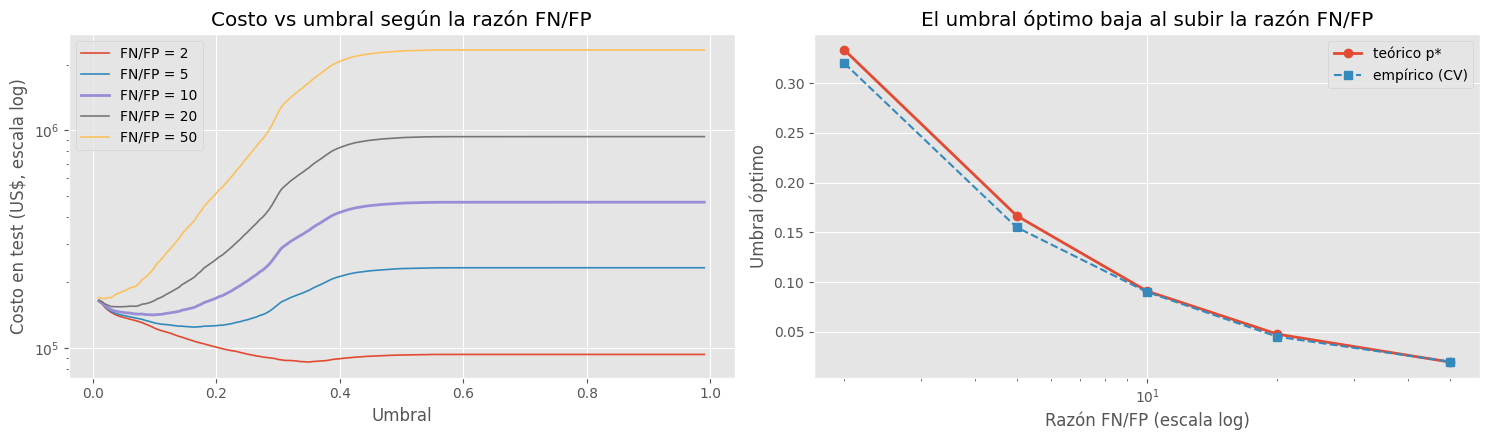

In [ ]:
#Gráfico de sensibilidad y lectura
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))

# Izquierda: curva de costo vs umbral para cada razón (escala log para que se vean todas)
for razon, c in curvas.items():
    ax[0].plot(umbrales, c, label=f"FN/FP = {razon}", lw=2 if razon == 10 else 1.2)
ax[0].set_yscale("log")
ax[0].set_xlabel("Umbral"); ax[0].set_ylabel("Costo en test (US$, escala log)")
ax[0].set_title("Costo vs umbral según la razón FN/FP"); ax[0].legend()

# Derecha: el umbral óptimo baja cuando el FN se encarece
ax[1].plot(sens["Razón FN/FP"], sens["Umbral teórico"], "o-", label="teórico p*", lw=2)
ax[1].plot(sens["Razón FN/FP"], sens["Umbral empírico"], "s--", label="empírico (CV)")
ax[1].set_xscale("log")
ax[1].set_xlabel("Razón FN/FP (escala log)"); ax[1].set_ylabel("Umbral óptimo")
ax[1].set_title("El umbral óptimo baja al subir la razón FN/FP"); ax[1].legend()

plt.tight_layout()
plt.savefig(f"{CARPETA}/sensibilidad.png", dpi=130)
plt.show()

**Lectura de la sensibilidad**
- **A mayor razón FN/FP, menor umbral óptimo** (conviene llamar a más gente) y **mayor ahorro** frente al umbral 0,5: de US\$ 5.265 (razón 2) a US\$ 2,1 millones (razón 50). Es la fórmula p* = 1 / (1 + razón).
- El **umbral teórico y el empírico coinciden** en todos los escenarios: las probabilidades en escala real están bien calibradas. Por eso el modelo con pesos se acerca al óptimo solo cuando la razón real está cerca de 7 (razones 5 y 10), y se aleja en los extremos.
- El **modelo con pesos (Etapa B)** empeora a medida que la razón crece (en razón 50 cuesta US\$ 299.610 vs US\$ 168.605 del umbral empírico): `class_weight="balanced"` equivale a una razón fija (~7) y **no se adapta a los costos del negocio**.
- **Solo importa la razón, no los montos:** usar (US\$ 5, US\$ 50) o (US\$ 20, US\$ 200) da el mismo umbral; los dólares sirven para comunicar el impacto a la gerencia.
- **Limitación:** se evaluó en una sola partición train/test; diferencias de pocos cientos de dólares entre el umbral teórico y el empírico son ruido.

### 8.1 Verificación: ¿las probabilidades son confiables?
La regla p* = C_FP / (C_FP + C_FN) solo funciona si las probabilidades del modelo son reales. Lo comprobamos con la curva de calibración (en test).

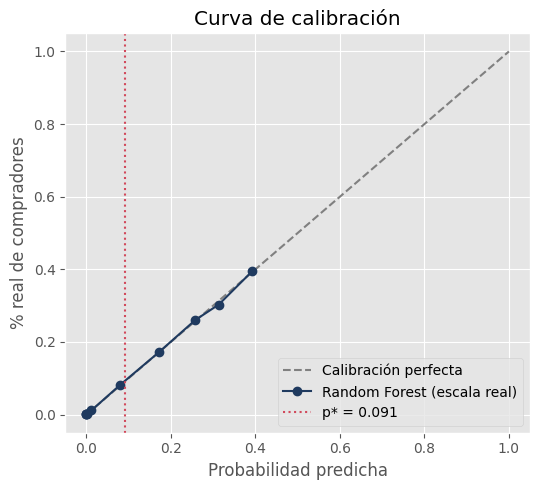

In [ ]:
# ¿Las probabilidades del modelo son confiables? (curva de calibración)
from sklearn.calibration import calibration_curve
frac_real, prob_media = calibration_curve(y_test, modelo_final.predict_proba(X_test)[:, 1],
                                          n_bins=10, strategy="quantile")
plt.figure(figsize=(5.5, 5))
plt.plot([0, 1], [0, 1], "--", color="gray", label="Calibración perfecta")
plt.plot(prob_media, frac_real, "o-", color="#1f3a5f", label="Random Forest (escala real)")
plt.axvline(P_STAR, ls=":", color="#d1495b", label=f"p* = {P_STAR:.3f}")
plt.xlabel("Probabilidad predicha"); plt.ylabel("% real de compradores")
plt.title("Curva de calibración"); plt.legend(); plt.tight_layout(); plt.show()

**Lectura:** los puntos quedan prácticamente **sobre la diagonal**: cuando el modelo predice ~10% de probabilidad, compra ~10% de esos clientes; cuando predice ~40%, compra ~40%. El modelo reentrenado en proporción real está **bien calibrado**, lo que explica por qué el umbral teórico (0,091) y el empírico (0,090) coinciden.

## 9. Dashboard: exportación de datos
Exportamos las probabilidades **en escala real** del test (`y_test`, `proba`) a un CSV. El dashboard las usa para recalcular en vivo el costo, la matriz de confusión y el umbral óptimo cuando la gerencia cambia los costos o mueve el umbral.

In [ ]:
# CSV que usa el dashboard: respuesta real + probabilidad en escala real (+ modelo con pesos, de referencia)
export = pd.DataFrame({"y_test": y_te,
                       "proba": proba_test.round(6),
                       "proba_pesos_etapa_B": proba_pesos.round(6)})
export.to_csv(f"{CARPETA}/predicciones_test.csv", index=False)
print("Exportado:", export.shape)
print("Archivos guardados en Drive:", sorted(os.listdir(CARPETA)))
export.head()

Exportado: (76168, 3)
Archivos guardados en Drive: ['comparacion_10.png', 'comparacion_umbrales_test.csv', 'costo_vs_umbral.png', 'derivacion_pstar.png', 'mejor_modelo.joblib', 'metadata.joblib', 'predicciones_test.csv', 'resultados_parciales.csv', 'roc_isocosto.png', 'sensibilidad.csv', 'sensibilidad.png', 'tabla_10_combinaciones.csv']


,y_test,proba,proba_pesos_etapa_B
0,0,0.000014,0.000440
1,0,0.141296,0.555658
2,0,0.088481,0.284053
3,0,0.109661,0.508993
4,0,0.021420,0.155725


## Conclusiones
1. **Pipeline sin fuga:** limpieza, codificación y SMOTE van dentro del pipeline; partición 80/20 estratificada con semilla fija. Se eliminaron 269 duplicados antes de la partición.
2. **Parte 1:** se compararon 5 modelos × 2 estrategias (10 combinaciones) con búsqueda de hiperparámetros y CV estratificada. El mejor por F1 CV fue **Random Forest con SMOTE** (0,4457 ± 0,0055), en empate técnico con Random Forest con pesos (0,4413). Los pesos logran un F1 similar en un tercio del tiempo y sin fabricar datos.
3. **Parte 2:** con C_FP = US\$ 5 y C_FN = US\$ 50, el umbral 0,5 cuesta casi lo mismo que no hacer nada. El **umbral empírico (0,090)**, casi igual al teórico (0,091), baja el costo a US\$ 142.115: **ahorro de US\$ 320.215 (69,3%)** en el test, ~US\$ 4,20 por cliente.
4. **Recomendación para el negocio:** llamar a todo cliente con probabilidad de compra ≥ 9%, y recalcular el umbral si cambian los costos (el dashboard lo hace en vivo).

**Limitaciones**
- Los costos son supuestos (apoyados en fuentes); la sensibilidad muestra su efecto.
- La búsqueda de hiperparámetros se hizo en una submuestra de 30.000 filas, y todo se evaluó en una sola partición train/test.
- SMOTE interpola después del one-hot y crea valores intermedios en las variables categóricas (SMOTENC lo evitaría).
- Menor recall en clientes menores de 30 años (0,84 vs ~0,98) y uso de variables sensibles (género, edad): hay que monitorear por grupo.